In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [2]:
df = pd.read_csv("../data/data_set.csv")

df.head()

,Order ID,Customer Name,Category,Sub Category,City,Order Date,Region,Sales,Discount,Profit,State
0,OD1,Harish,Oil & Masala,Masalas,Vellore,11-08-2017,North,1254,0.12,401.28,Tamil Nadu
1,OD2,Sudha,Beverages,Health Drinks,Krishnagiri,11-08-2017,South,749,0.18,149.80,Tamil Nadu
2,OD3,Hussain,Food Grains,Atta & Flour,Perambalur,06-12-2017,West,2360,0.21,165.20,Tamil Nadu
3,OD4,Jackson,Fruits & Veggies,Fresh Vegetables,Dharmapuri,10-11-2016,South,896,0.25,89.60,Tamil Nadu
4,OD5,Ridhesh,Food Grains,Organic Staples,Ooty,10-11-2016,South,2355,0.26,918.45,Tamil Nadu


In [3]:
df.shape

(9994, 11)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       9994 non-null   str    
 1   Customer Name  9994 non-null   str    
 2   Category       9994 non-null   str    
 3   Sub Category   9994 non-null   str    
 4   City           9994 non-null   str    
 5   Order Date     9994 non-null   str    
 6   Region         9994 non-null   str    
 7   Sales          9994 non-null   int64  
 8   Discount       9994 non-null   float64
 9   Profit         9994 non-null   float64
 10  State          9994 non-null   str    
dtypes: float64(2), int64(1), str(8)
memory usage: 859.0 KB


## Revision inicial del dataset

El dataset contiene **9,994 registros y 11 columnas**.

Al revisar la informacion con `df.info()` se observa que:

- No existen valores nulos, ya que todas las columnas cuentan con 9,994 datos.
- La columna `Sales` es de tipo entero.
- Las columnas `Discount` y `Profit` son de tipo decimal.
- Las demas columnas son de tipo texto.
- La columna `Order Date` aparece como texto, por lo que sera necesario convertirla a formato de fecha para poder analizar correctamente la informacion a lo largo del tiempo.



In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order ID       9994 non-null   str           
 1   Customer Name  9994 non-null   str           
 2   Category       9994 non-null   str           
 3   Sub Category   9994 non-null   str           
 4   City           9994 non-null   str           
 5   Order Date     4042 non-null   datetime64[us]
 6   Region         9994 non-null   str           
 7   Sales          9994 non-null   int64         
 8   Discount       9994 non-null   float64       
 9   Profit         9994 non-null   float64       
 10  State          9994 non-null   str           
dtypes: datetime64[us](1), float64(2), int64(1), str(7)
memory usage: 859.0 KB


In [7]:
df["Order Date"].isnull().sum()

np.int64(5952)

## Revision de duplicados y fechas

Se revisaron los registros duplicados mediante `df.duplicated().sum()`.

El resultado fue **0**, por lo que el dataset no contiene filas duplicadas.

Posteriormente se intento convertir la columna `Order Date` a formato de fecha. Sin embargo, se detecto que el dataset utiliza diferentes formatos de fecha, por ejemplo:

- `11-08-2017`
- `4/15/2018`
- `11/22/2016`

Debido a esta mezcla de formatos, la primera conversion genero **5,952 valores nulos** en la columna `Order Date`.



In [8]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="mixed",
    errors="coerce"
)

df["Order Date"].isnull().sum()

np.int64(5952)

In [ ]:
import pandas as pd


df = pd.read_csv("../data/data_set.csv")

# Convertir fechas aceptando formatos diferentes para que pase lo que nos paso en el codgio anterior
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="mixed",
    errors="coerce"
)


df["Order Date"].isnull().sum()

np.int64(0)

## Revision de duplicados y fechas

Primero revisamos si habia filas duplicadas con `df.duplicated().sum()`.

El resultado fue **0**, asi que no habia filas duplicadas.

Despues intentamos convertir la columna `Order Date` a formato de fecha, pero vimos que muchas fechas quedaron como nulas.

Esto paso porque las fechas venian escritas de diferentes formas, unas con `/` y otras con `-`.

Por eso volvimos a cargar el dataset original y usamos `format="mixed"` para que Pandas pudiera reconocer los diferentes formatos de fecha.

Al final volvimos a revisar los nulos y el resultado fue **0**, por lo que todas las fechas quedaron cargadas correctamente.

In [10]:
df.describe()

,Order Date,Sales,Discount,Profit
count,9994,9994.000000,9994.000000,9994.000000
mean,2017-04-30 05:17:08.056834,1496.596158,0.226817,374.937082
min,2015-01-03 00:00:00,500.000000,0.100000,25.250000
25%,2016-05-23 00:00:00,1000.000000,0.160000,180.022500
50%,2017-06-26 00:00:00,1498.000000,0.230000,320.780000
75%,2018-05-14 00:00:00,1994.750000,0.290000,525.627500
max,2018-12-30 00:00:00,2500.000000,0.350000,1120.950000
std,NaN,577.559036,0.074636,239.932881


In [11]:
df["Category"].value_counts()

Category
Snacks               1514
Eggs, Meat & Fish    1490
Fruits & Veggies     1418
Bakery               1413
Beverages            1400
Food Grains          1398
Oil & Masala         1361
Name: count, dtype: int64

In [12]:
df["Sub Category"].value_counts()

Sub Category
Health Drinks         719
Soft Drinks           681
Cookies               520
Breads & Buns         502
Chocolates            499
Noodles               495
Masalas               463
Biscuits              459
Cakes                 452
Edible Oil & Ghee     451
Spices                447
Mutton                394
Eggs                  379
Organic Staples       372
Fresh Fruits          369
Fish                  369
Fresh Vegetables      354
Atta & Flour          353
Chicken               348
Organic Fruits        348
Organic Vegetables    347
Dals & Pulses         343
Rice                  330
Name: count, dtype: int64

In [13]:
resumen_categoria = df.groupby("Category").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Discount": "mean"
}).sort_values("Sales", ascending=False)

resumen_categoria

,Sales,Profit,Discount
Category,,,
"Eggs, Meat & Fish",2267401,567357.22,0.227792
Snacks,2237546,568178.85,0.222048
Food Grains,2115272,529162.64,0.228548
Bakery,2112281,528521.06,0.225428
Fruits & Veggies,2100727,530400.38,0.229295
Beverages,2085313,525605.76,0.230329
Oil & Masala,2038442,497895.29,0.224526


## Analisis por categoria

Agrupamos los datos por categoria y calculamos:

- Ventas totales.
- Ganancia total.
- Descuento promedio.

Los resultados muestran que **Eggs, Meat & Fish** tiene las ventas mas altas.

Tambien vimos que **Snacks** tiene ventas muy altas y una ganancia incluso un poco mayor.

En general, los descuentos promedio son parecidos entre todas las categorias.



In [14]:
resumen_subcategoria = df.groupby("Sub Category").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Discount": "mean"
}).sort_values("Sales", ascending=False)

resumen_subcategoria

,Sales,Profit,Discount
Sub Category,,,
Health Drinks,1051439,267469.79,0.231558
Soft Drinks,1033874,258135.97,0.229031
Cookies,768213,190643.70,0.218692
Breads & Buns,742586,190764.98,0.226494
Noodles,735435,193685.81,0.221939
Chocolates,733898,183849.34,0.225651
Masalas,697480,168999.11,0.223866
Cakes,685612,168398.46,0.224646
Biscuits,684083,169357.62,0.225033


## Analisis por subcategoria

Agrupamos los datos por `Sub Category` para comparar el rendimiento de cada tipo de producto.

Calculamos las ventas totales, la ganancia total y el descuento promedio de cada subcategoria.

Despues ordenamos los resultados de mayor a menor segun las ventas.

Vimos que **Health Drinks** tiene las ventas y ganancias mas altas, seguido de **Soft Drinks**.



In [15]:
promedio_ventas = resumen_subcategoria["Sales"].mean()
promedio_ganancia = resumen_subcategoria["Profit"].mean()

print("Promedio de ventas:", promedio_ventas)
print("Promedio de ganancia:", promedio_ganancia)

Promedio de ventas: 650303.5652173914
Promedio de ganancia: 162918.3130434783


## Reglas para generar recomendaciones

Despues de analizar las ventas y ganancias por subcategoria, vamos a comparar cada una contra los promedios generales.

El sistema usara estas reglas:

- Ventas altas y ganancia alta: aumentar disponibilidad.
- Ventas altas y ganancia baja: revisar costos o descuentos.
- Ventas bajas y ganancia alta: mantener el producto y promocionarlo.
- Ventas bajas y ganancia baja: reducir inventario o aplicar una promocion.



In [17]:
def recomendar(fila):
    if fila["Sales"] >= promedio_ventas and fila["Profit"] >= promedio_ganancia:
        return "Aumentar disponibilidad"
    
    elif fila["Sales"] >= promedio_ventas and fila["Profit"] < promedio_ganancia:
        return "Revisar costos o descuentos"
    
    elif fila["Sales"] < promedio_ventas and fila["Profit"] >= promedio_ganancia:
        return "Mantener y promocionar"
    
    else:
        return "Reducir inventario o aplicar promocion"

In [19]:
resumen_subcategoria["Recomendacion"] = resumen_subcategoria.apply(
    recomendar,
    axis=1
)

resumen_subcategoria

,Sales,Profit,Discount,Recomendacion
Sub Category,,,,
Health Drinks,1051439,267469.79,0.231558,Aumentar disponibilidad
Soft Drinks,1033874,258135.97,0.229031,Aumentar disponibilidad
Cookies,768213,190643.70,0.218692,Aumentar disponibilidad
Breads & Buns,742586,190764.98,0.226494,Aumentar disponibilidad
Noodles,735435,193685.81,0.221939,Aumentar disponibilidad
Chocolates,733898,183849.34,0.225651,Aumentar disponibilidad
Masalas,697480,168999.11,0.223866,Aumentar disponibilidad
Cakes,685612,168398.46,0.224646,Aumentar disponibilidad
Biscuits,684083,169357.62,0.225033,Aumentar disponibilidad


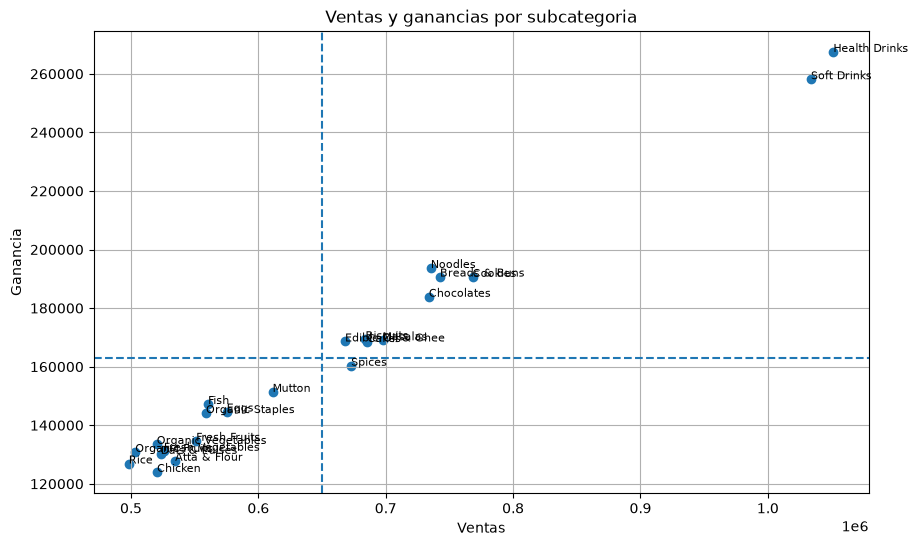

In [22]:
plt.figure(figsize=(10, 6))

plt.scatter(
    resumen_subcategoria["Sales"],
    resumen_subcategoria["Profit"]
)

plt.axvline(promedio_ventas, linestyle="--")
plt.axhline(promedio_ganancia, linestyle="--")

for nombre, fila in resumen_subcategoria.iterrows():
    plt.text(
        fila["Sales"],
        fila["Profit"],
        nombre,
        fontsize=8
    )

plt.title("Ventas y ganancias por subcategoria")
plt.xlabel("Ventas")
plt.ylabel("Ganancia")
plt.grid()

plt.show()

## Grafica de ventas y ganancias

Creamos una grafica para comparar las ventas y ganancias de cada subcategoria.

Cada punto representa una subcategoria.

Tambien agregamos una linea para el promedio de ventas y otra para el promedio de ganancias.

Estas lineas dividen la grafica en cuatro zonas y nos ayudan a ver que recomendacion corresponde a cada subcategoria.

Con esto podemos identificar de forma visual cuales productos necesitan mayor disponibilidad, promocion, revision de costos o reduccion de inventario.

In [24]:
tabla_final = resumen_subcategoria[
    ["Sales", "Profit", "Discount", "Recomendacion"]
].copy()

tabla_final

,Sales,Profit,Discount,Recomendacion
Sub Category,,,,
Health Drinks,1051439,267469.79,0.231558,Aumentar disponibilidad
Soft Drinks,1033874,258135.97,0.229031,Aumentar disponibilidad
Cookies,768213,190643.70,0.218692,Aumentar disponibilidad
Breads & Buns,742586,190764.98,0.226494,Aumentar disponibilidad
Noodles,735435,193685.81,0.221939,Aumentar disponibilidad
Chocolates,733898,183849.34,0.225651,Aumentar disponibilidad
Masalas,697480,168999.11,0.223866,Aumentar disponibilidad
Cakes,685612,168398.46,0.224646,Aumentar disponibilidad
Biscuits,684083,169357.62,0.225033,Aumentar disponibilidad


In [25]:
tabla_final["Sales"] = tabla_final["Sales"].round(2)
tabla_final["Profit"] = tabla_final["Profit"].round(2)
tabla_final["Discount"] = (tabla_final["Discount"] * 100).round(2)

tabla_final

,Sales,Profit,Discount,Recomendacion
Sub Category,,,,
Health Drinks,1051439,267469.79,23.16,Aumentar disponibilidad
Soft Drinks,1033874,258135.97,22.90,Aumentar disponibilidad
Cookies,768213,190643.70,21.87,Aumentar disponibilidad
Breads & Buns,742586,190764.98,22.65,Aumentar disponibilidad
Noodles,735435,193685.81,22.19,Aumentar disponibilidad
Chocolates,733898,183849.34,22.57,Aumentar disponibilidad
Masalas,697480,168999.11,22.39,Aumentar disponibilidad
Cakes,685612,168398.46,22.46,Aumentar disponibilidad
Biscuits,684083,169357.62,22.50,Aumentar disponibilidad


## Resultado final

Al final creamos una tabla donde se muestran las ventas, ganancias, descuento promedio y la recomendacion para cada subcategoria.

Esta tabla representa la salida principal del sistema.

Con base en los datos analizados, el sistema genera una recomendacion que puede ser usada para tomar una decision sobre cada tipo de producto.


In [26]:
tabla_final.to_csv(
    "../resultados/recomendaciones_finales.csv",
    index=True
)

print("Archivo guardado correctamente")

Archivo guardado correctamente
